In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

In [16]:
# Import Data
df_cases = pd.read_csv("../data/bangkok_dengue_1993_2023.csv")
df_weather = pd.read_csv("../data/weekly_data.csv")

# Format to datetime
df_cases["calendar_start_date"] = pd.to_datetime(df_cases["calendar_start_date"])
df_cases["calendar_end_date"] = pd.to_datetime(df_cases["calendar_end_date"])
df_cases = df_cases.sort_values("calendar_start_date")

df_weather["valid_time"] = pd.to_datetime(df_weather["valid_time"])
df_weather = df_weather.sort_values("valid_time")

# Create a monthly matching column in each dataframe
df_weather["month"] = df_weather["valid_time"].dt.to_period("M")
df_cases["month"] = df_cases["calendar_end_date"].dt.to_period("M")

# Merge monthly dengue totals onto each weekly weather observation
df_combined = df_weather.merge(
    df_cases[["month", "dengue_total"]],
    on="month",
    how="left"
)

df_combined = df_combined.sort_values("valid_time").reset_index(drop=True)
df_combined = df_combined.drop(columns=["month", "latitude", "longitude"])

weather_cols = [
    col for col in df_combined.columns
    if col not in ["valid_time", "dengue_total"]
]

# Monthly dengue case counts
monthly_cases = (
    df_combined.assign(
        month=df_combined["valid_time"].dt.to_period("M")
    )
    .drop_duplicates("month")
    .dropna()
    .set_index("month")["dengue_total"]
    .sort_index()
)

# Input columns: weather + historical dengue cases
input_cols = weather_cols + ["dengue_total"]

df_combined.head(10)

,valid_time,d2m,t2m,tp,dengue_total
0,1993-01-03,294.047634,300.266561,0.000196,194.0
1,1993-01-10,292.710655,300.161210,0.000026,194.0
2,1993-01-17,294.799441,300.824044,0.001966,194.0
3,1993-01-24,294.909541,300.735656,0.006118,194.0
4,1993-01-31,286.753935,296.970963,0.002281,194.0
5,1993-02-07,287.174452,298.823327,0.000000,159.0
6,1993-02-14,294.459790,300.398823,0.000630,159.0
7,1993-02-21,294.526880,300.922179,0.002067,159.0
8,1993-02-28,294.815038,301.672267,0.000342,159.0
9,1993-03-07,296.358405,302.082197,0.005665,175.0


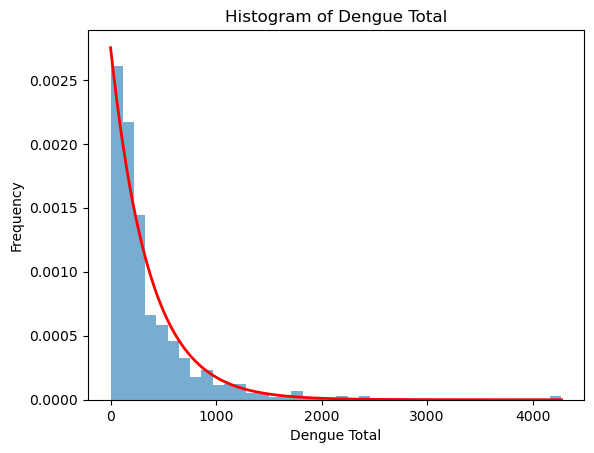

In [17]:
c = np.mean(df_combined["dengue_total"])
x = np.linspace(0, df_combined["dengue_total"].max(), 1000)
y = (1/c) * np.exp(-x/c)

plt.hist(df_combined["dengue_total"], bins=40, density=True, alpha=0.6)
plt.plot(x, y, 'r', linewidth=2)
plt.xlabel("Dengue Total")
plt.ylabel("Frequency")
plt.title("Histogram of Dengue Total")
plt.show()

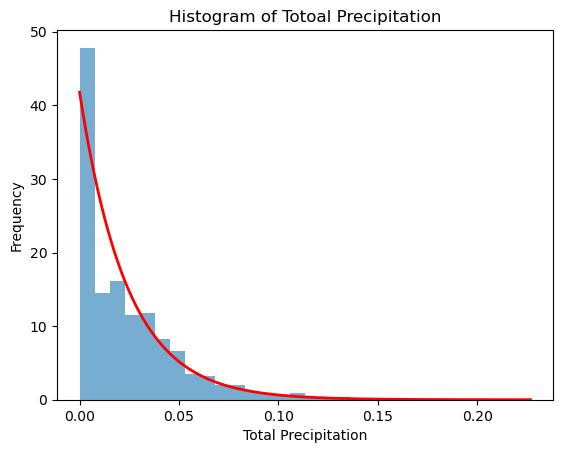

In [18]:
omega = np.mean(df_combined["tp"])
x = np.linspace(0, df_combined["tp"].max(), 1000)
y = (1/omega) * np.exp(-x/omega)

plt.hist(df_combined["tp"], bins=30, density=True, alpha=0.6)
plt.plot(x, y, 'r', linewidth=2)
plt.xlabel("Total Precipitation")
plt.ylabel("Frequency")
plt.title("Histogram of Totoal Precipitation")
plt.show()


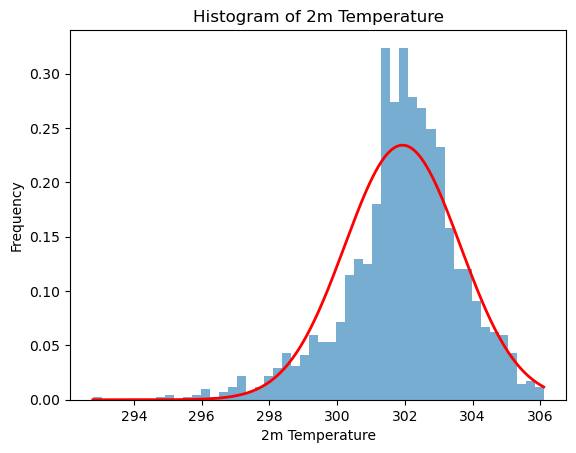

In [24]:
tbar = np.mean(df_combined["t2m"])
s = np.std(df_combined["t2m"])
x = np.linspace(df_combined["t2m"].min(), df_combined["t2m"].max(), 1000)
y = stats.norm.pdf(x, tbar, s)

plt.hist(df_combined["t2m"], bins=50, density=True, alpha=0.6)
plt.plot(x, y, 'r', linewidth=2)
plt.xlabel("2m Temperature")
plt.ylabel("Frequency")
plt.title("Histogram of 2m Temperature")
plt.show()

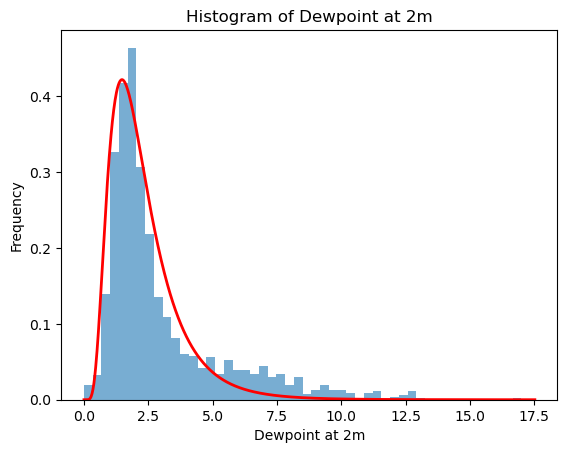

In [88]:

m = np.max(df_combined["d2m"])
tbar = np.max(m - np.mean(df_combined["d2m"]))

s = np.std(df_combined["d2m"])
x = np.linspace((m - df_combined["d2m"]).min(), (300 - df_combined["d2m"]).max(), 1000)
y = stats.lognorm.pdf(x, s=0.55, scale=2)

plt.hist(m - df_combined["d2m"], bins=50, density=True, alpha=0.6)
plt.plot(x, y, 'r', linewidth=2)
plt.xlabel("Dewpoint at 2m")
plt.ylabel("Frequency")
plt.title("Histogram of Dewpoint at 2m")
plt.show()

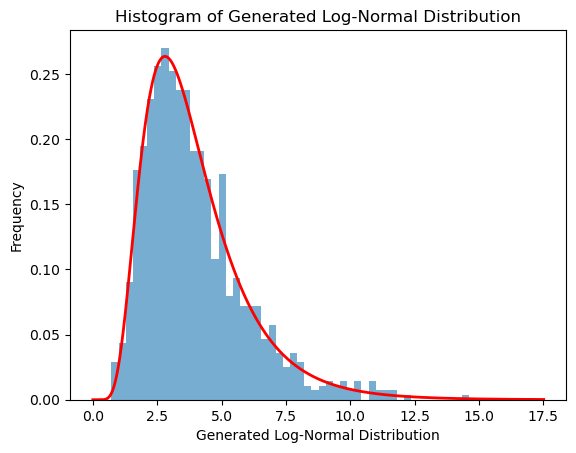

In [89]:
z = np.log(m - df_combined["d2m"] + 1)
mu = np.mean(z)
sigma = np.std(z)

X = np.random.normal(mu, sigma, 1000)

plt.hist(np.exp(X), bins=50, density=True, alpha=0.6)
plt.xlabel("Generated Log-Normal Distribution")
plt.ylabel("Frequency")
# x = np.linspace(np.exp(X).min(), np.exp(X).max(), 1000)
y = stats.lognorm.pdf(x, s=sigma, loc=0, scale=np.exp(mu))
plt.plot(x, y, 'r', linewidth=2)
plt.title("Histogram of Generated Log-Normal Distribution")
plt.show()



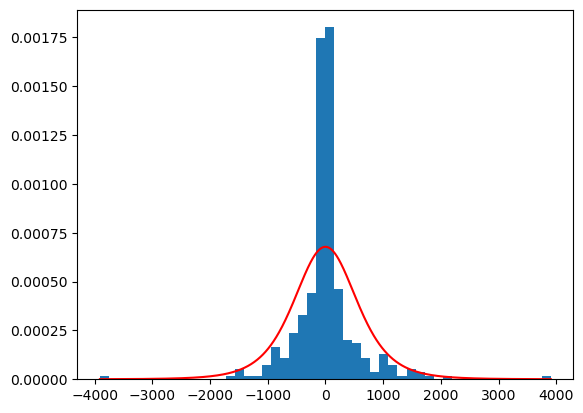